In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [57]:
sns.set_style("whitegrid")
sns.set_palette("viridis")
df = pd.read_csv("data/AI_Usage_and_Impact_on_Students_and_Professionals.csv")

df.head()

,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,AI_Usage_Hours_Per_Day,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend
0,U0269,30,Male,United Kingdom,Professional,Master's,Business Analyst,5421,ChatGPT,Office Work,2 hrs,Data analysis using AI-powered analytics tools...,NaN,5.3,4.0,7.0,3.9,7.3,Yes
1,U0217,30,Male,United States,Professional,Bachelor's,Customer Support Specialist,8903,ChatGPT,Customer Support,5.7,Resolving customer inquiries using AI chatbot ...,0,9.9,3.0,9.0,11.4,8.4 hrs,Yes
2,U0152,17,Male,Canada,Student,NaN,Computer Science Student,402,Chat GPT,Coding,1 hrs,NaN,20,3.2,2.0,4.0,5.2,6.7,No
3,U0264,35,FEMALE,Brazil,Professional,Bachelor's,Desenvolvedora de Software / Software Developer,1367,Meta AI,Coding,1.7,"Usar GitHub Copilot para autocompletar código,...",20,5.6,4.0,5.0,6.4,9.6,Maybe
4,U0263,19,Female,Canada,Student,Undergraduate,Biology Student,438,Perplexity AI,NaN,4.1,Using AI to generate study summaries for exam ...,0,4.7,4.0,7.0,9.2,6.2,Yes


In [58]:
df.columns

Index(['User_ID', 'Age', 'Gender', 'Country', 'User_Type', 'Education_Level',
       'Profession', 'Monthly_Income', 'AI_Tool', 'AI_Purpose',
       'AI_Usage_Hours_Per_Day', 'Tasks_Performed', 'Monthly_AI_Cost',
       'Productivity_Score', 'Accuracy_Rating', 'Satisfaction_Score',
       'Time_Saved_Hours_Per_Week', 'Work_or_Study_Hours_Per_Day',
       'Would_Recommend'],
      dtype='str')

In [59]:
df.describe()

,Productivity_Score,Accuracy_Rating,Satisfaction_Score
count,284.000000,285.000000,293.000000
mean,5.230282,3.428070,6.146758
std,1.817193,0.855338,1.517805
min,1.600000,2.000000,3.000000
25%,3.900000,3.000000,5.000000
50%,5.000000,4.000000,6.000000
75%,6.500000,4.000000,7.000000
max,10.000000,5.000000,10.000000


In [60]:
# Standardize AI tool names
df["AI_Tool"] = df["AI_Tool"].astype("string")

df["AI_Tool"] = df["AI_Tool"].str.replace(r"(?i)^chat ?gpt$", "ChatGPT", regex=True)
df["AI_Tool"] = df["AI_Tool"].str.replace(r"(?i)^claude$", "Claude", regex=True)
df["AI_Tool"] = df["AI_Tool"].str.replace(r"(?i)^microsoft copilot$|^copilot$", "Microsoft Copilot", regex=True)
df["AI_Tool"] = df["AI_Tool"].str.replace(r"(?i)^google gemini$|^gemini$", "Google Gemini", regex=True)

# Optional: keep the set in sync with cleaned values
llms = set(df["AI_Tool"].dropna().unique())
llms


{'ChatGPT',
 'Claude',
 'DeepSeek',
 'Google Gemini',
 'Grammarly',
 'Meta AI',
 'Microsoft Copilot',
 'Perplexity AI'}

In [61]:
df["Monthly_AI_Cost"] = pd.to_numeric(df["Monthly_AI_Cost"], errors="coerce")
df["Satisfaction_Score"] = pd.to_numeric(df["Satisfaction_Score"], errors="coerce")

mean_cost_by_tool = (
    df.groupby("AI_Tool")["Monthly_AI_Cost"]
      .mean()
      .reset_index(name="Median_Monthly_Cost")
)

mean_satisfaction_per_tool = (
    df.groupby("AI_Tool")["Satisfaction_Score"]
      .mean()
      .reset_index(name="Mean_Satisfaction_Score")
)

mean_cost_by_tool, mean_satisfaction_per_tool

(             AI_Tool  Median_Monthly_Cost
 0            ChatGPT             9.259259
 1             Claude            14.137931
 2           DeepSeek            11.875000
 3      Google Gemini             8.750000
 4          Grammarly            13.636364
 5            Meta AI             7.777778
 6  Microsoft Copilot             8.970588
 7      Perplexity AI             7.400000,
              AI_Tool  Mean_Satisfaction_Score
 0            ChatGPT                 6.237288
 1             Claude                 6.096774
 2           DeepSeek                 6.333333
 3      Google Gemini                 5.725000
 4          Grammarly                 6.285714
 5            Meta AI                 6.100000
 6  Microsoft Copilot                 6.305556
 7      Perplexity AI                 5.916667)

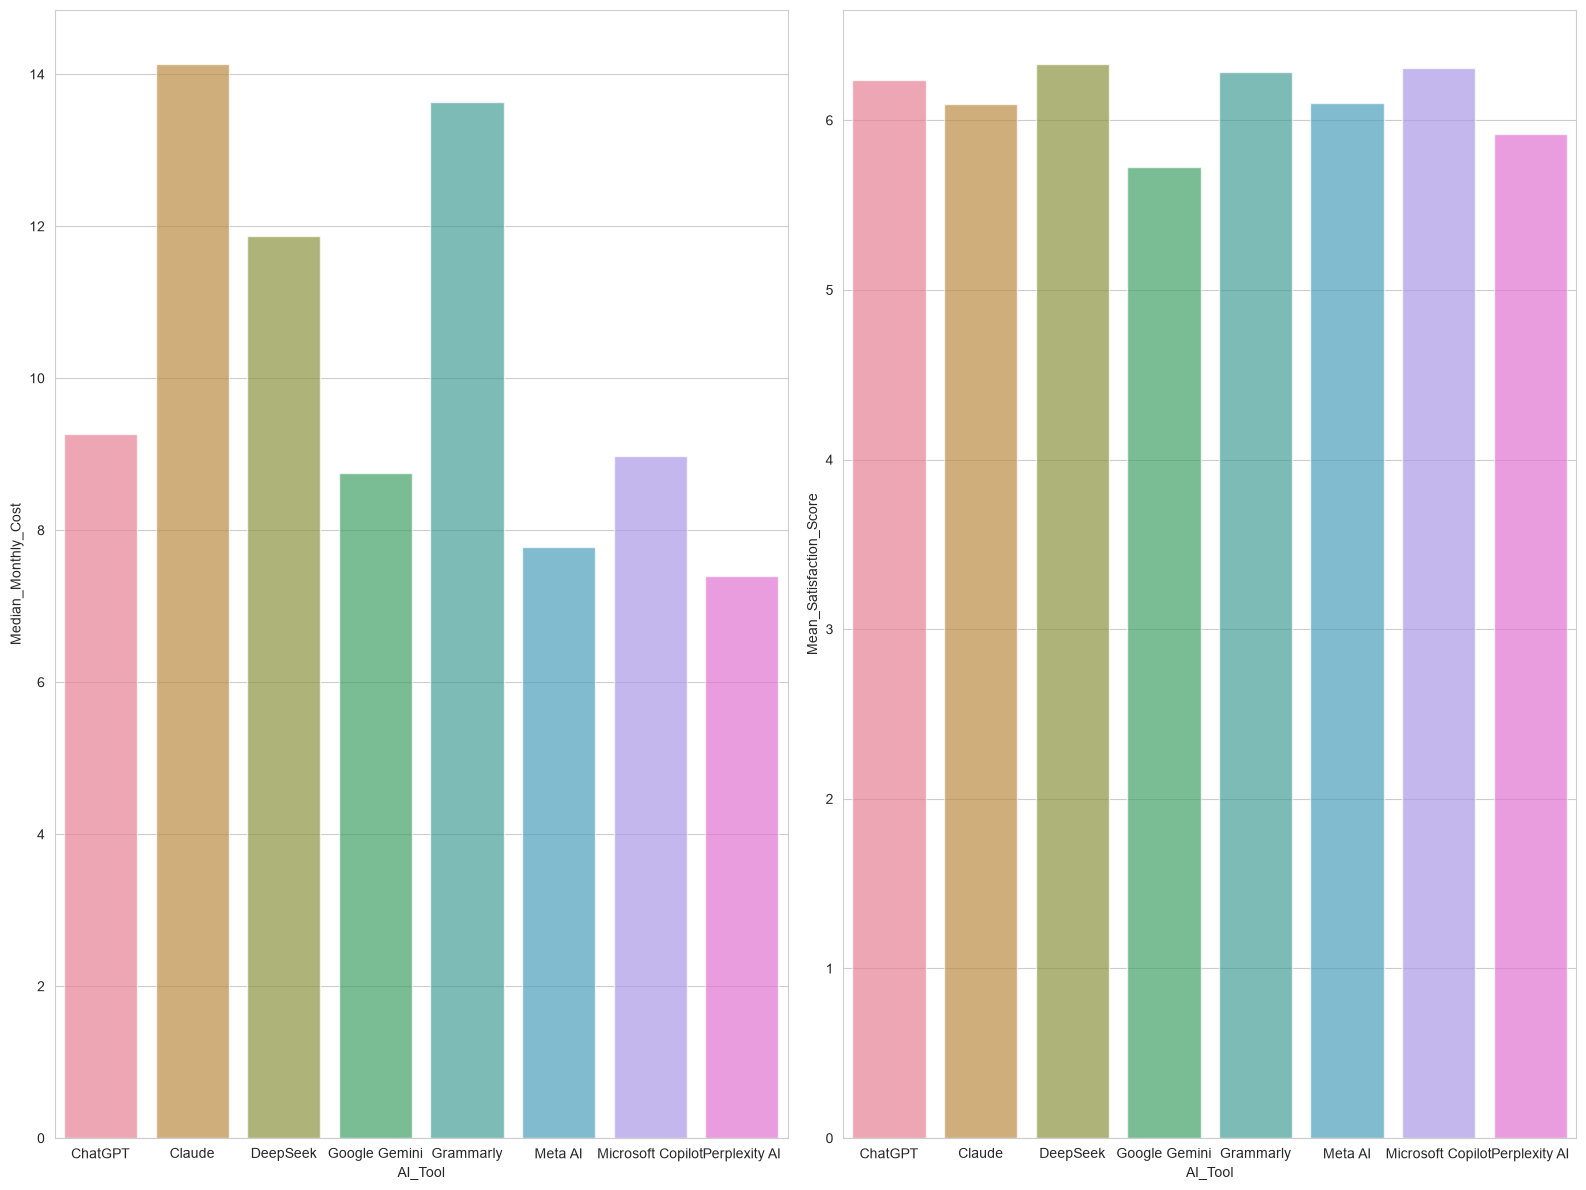

In [62]:
metrics = pd.merge(mean_cost_by_tool, mean_satisfaction_per_tool, on="AI_Tool")

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16,12))
sns.barplot(data=metrics, x="AI_Tool", y="Median_Monthly_Cost", alpha=0.7, hue="AI_Tool",ax=ax[0])
sns.barplot(data=metrics, x="AI_Tool", y="Mean_Satisfaction_Score", alpha=0.7, hue="AI_Tool",ax=ax[1])

plt.tight_layout()
plt.show()

Text(0, 0.5, 'Count')

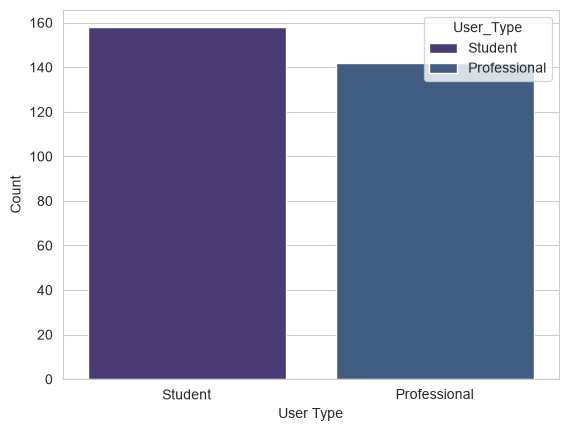

In [63]:
# most frequent user group
user_group_counts = df["User_Type"].value_counts()

sns.barplot(
    data=user_group_counts.reset_index(name="Amount"),
    x="User_Type",
    y="Amount",
    hue="User_Type",
    legend=True,
)

plt.xlabel("User Type")
plt.ylabel("Count")

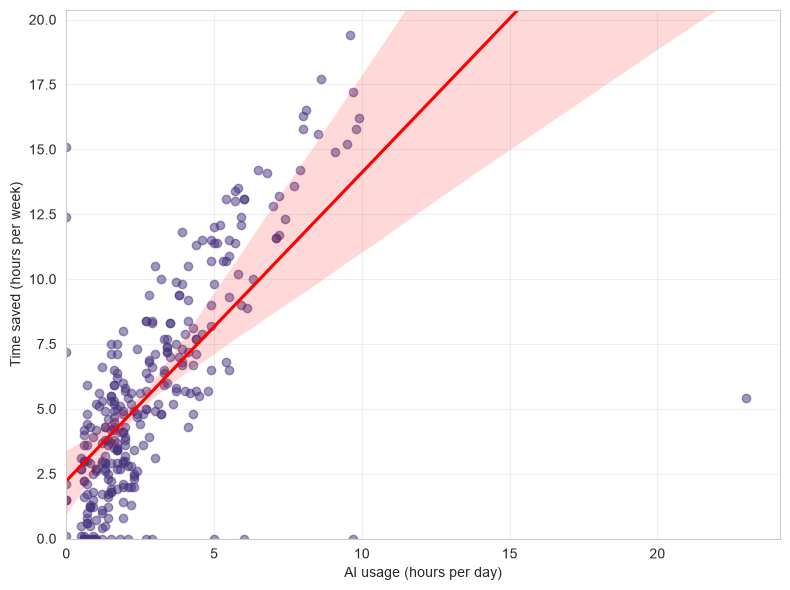

In [64]:
for col in ["AI_Usage_Hours_Per_Day", "Time_Saved_Hours_Per_Week"]:
    df[col] = pd.to_numeric(
        df[col].astype("string").str.extract(r"([-+]?\d*\.?\d+)")[0],
        errors="coerce"
    )

plot_df = df[["AI_Usage_Hours_Per_Day", "Time_Saved_Hours_Per_Week"]].fillna(0)

fig, ax_plot = plt.subplots(figsize=(8, 6))

sns.regplot(
    data=plot_df,
    x="AI_Usage_Hours_Per_Day",
    y="Time_Saved_Hours_Per_Week",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"},
    ax=ax_plot,
)

ax_plot.set_xscale("linear")
ax_plot.set_yscale("linear")
ax_plot.set_xlim(left=0, right=plot_df["AI_Usage_Hours_Per_Day"].max() * 1.05)
ax_plot.set_ylim(bottom=0, top=plot_df["Time_Saved_Hours_Per_Week"].max() * 1.05)
ax_plot.set_xlabel("AI usage (hours per day)")
ax_plot.set_ylabel("Time saved (hours per week)")
ax_plot.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

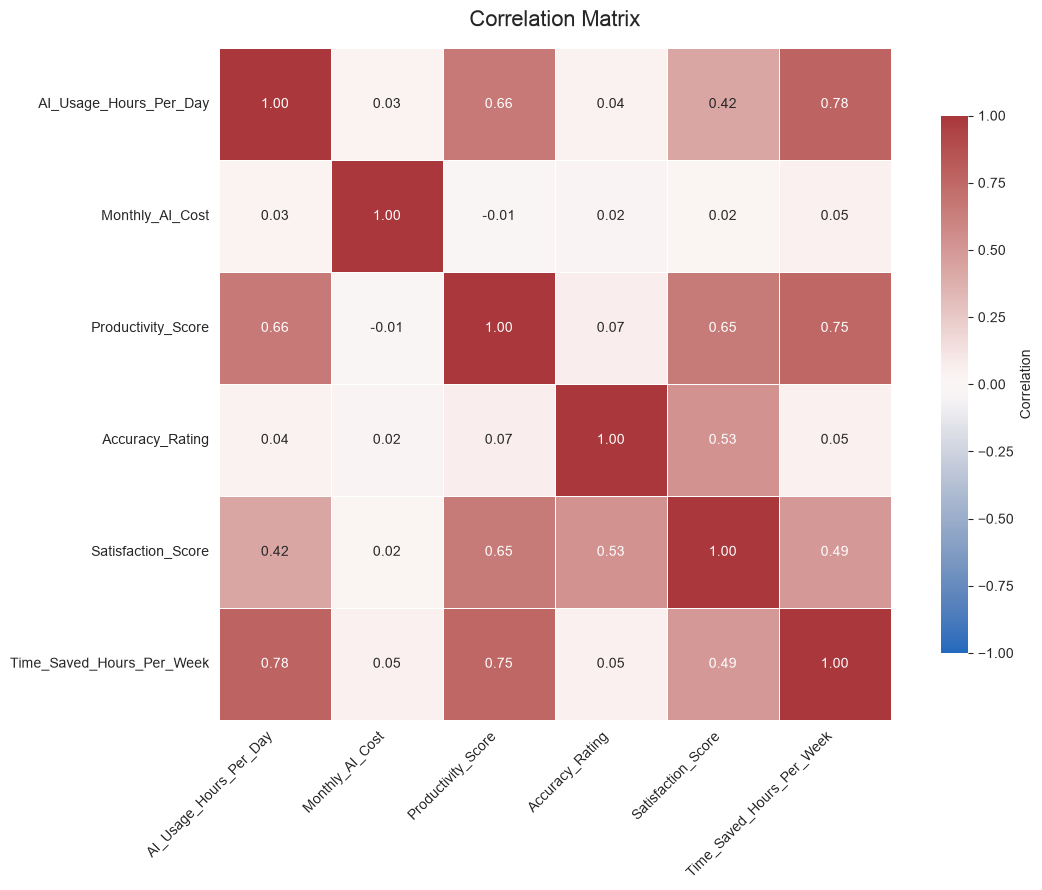

In [65]:
mtx = df.corr(numeric_only=True)

plt.figure(figsize=(12, 9))
sns.heatmap(
    mtx,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    cbar_kws={"shrink": 0.8, "label": "Correlation"},
)

plt.title("Correlation Matrix", fontsize=16, pad=16)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Clean the hours columns

In [66]:
numeric_cols = [
    "Age",
    "AI_Usage_Hours_Per_Day",
    "Time_Saved_Hours_Per_Week",
    "Work_or_Study_Hours_Per_Day",
]

for col in numeric_cols:
    df[col] = pd.to_numeric(
        df[col].astype("string").str.replace(r"\s*(?:yrs|hrs)\s*$", "", regex=True, case=False),
        errors="coerce",
    )

In [67]:
for column in df.columns:
    if df[column].dtype == "Float64" or df[column].dtype == "Int64":
        df[column] = df[column].fillna(df[column].median())
    if df[column].dtype == "string":
        df[column] = df[column].fillna(df[column].mode()[0])

df.dtypes, df.isna().sum()

(User_ID                            str
 Age                              Int64
 Gender                             str
 Country                            str
 User_Type                          str
 Education_Level                    str
 Profession                         str
 Monthly_Income                     str
 AI_Tool                         string
 AI_Purpose                         str
 AI_Usage_Hours_Per_Day         Float64
 Tasks_Performed                    str
 Monthly_AI_Cost                float64
 Productivity_Score             float64
 Accuracy_Rating                float64
 Satisfaction_Score             float64
 Time_Saved_Hours_Per_Week      Float64
 Work_or_Study_Hours_Per_Day    Float64
 Would_Recommend                    str
 dtype: object,
 User_ID                         0
 Age                             0
 Gender                          0
 Country                         0
 User_Type                       0
 Education_Level                 0
 Profession   

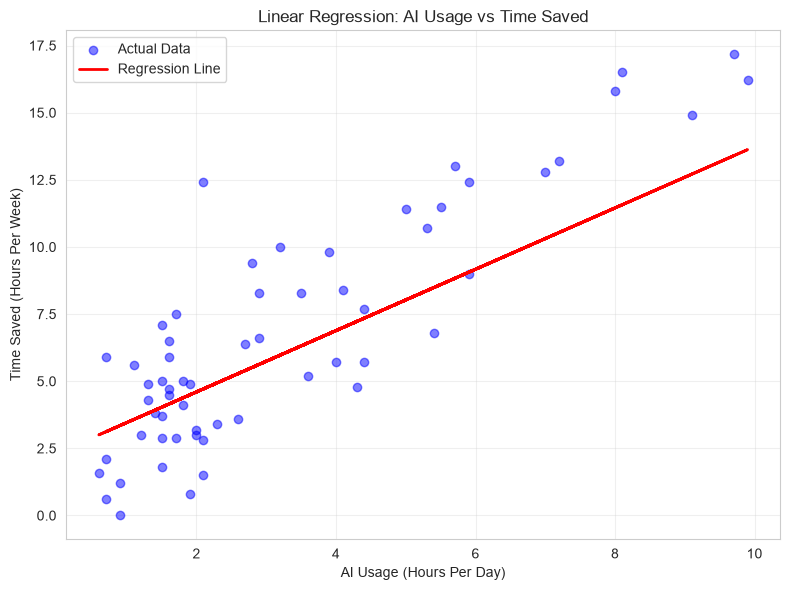

In [69]:
# Linear Regressio for predicting Time_Saved_Hours_Per_Week based on AI_Usage_Hours_Per_Day
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

X = df[["AI_Usage_Hours_Per_Day"]]
y = df[["Time_Saved_Hours_Per_Week"]]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression().fit(X_train, y_train)

# --- EVALUATION ---
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

def summary_lin_reg(model=model, X_train=X_train, y_train=y_train) -> pd.DataFrame:

    if model is None or X_train is None or y_train is None:
        raise ValueError("Model, X_train, and y_train must be provided.")
    # display the params
    coefficients = model.coef_[0]
    intercept = model.intercept_[0]
    r_squared = model.score(X_test, y_test)
    t_tests = []

    # calculate t-tests for siginificance of coefficients
    for i, coef in enumerate(coefficients):
        se = np.sqrt(np.sum((y_train - model.predict(X_train)) ** 2) / (len(y_train) - len(coefficients) - 1)) / np.sqrt(np.sum((X_train.iloc[:, i] - X_train.iloc[:, i].mean()) ** 2))
        t_stat = coef / se
        t_tests.append(t_stat)
    
    summary_df = pd.DataFrame({
        "Coefficient": coefficients,
        "Intercept": [intercept],
        "R-squared": [r_squared],
        "T_test": t_tests
    })

    return summary_df

summary = summary_lin_reg()
summary

# PLOTTING SECTION
plt.figure(figsize=(8, 6))
plt.scatter(X_test, y_test, color="blue", alpha=0.5, label="Actual Data")
plt.plot(X_test, y_pred, color="red", linewidth=2, label="Regression Line")
plt.title("Linear Regression: AI Usage vs Time Saved")
plt.xlabel("AI Usage (Hours Per Day)")
plt.ylabel("Time Saved (Hours Per Week)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Judging by the Linear Regressio model we can estimate that for every hour of AI used we save about 1.14 hours per week.